# Walkthrough: forecasting Indian paint revenue, honestly

**Question.** Can historical financial and operational data of Indian paint companies predict next-period revenue?

**How this notebook answers it**
1. Load 12 years of reported financials (4 companies, 211 official filings).
2. Reframe the target as *year-on-year growth of the next quarter*, so models cannot win by knowing which company is big.
3. Judge every model in a **walk-forward backtest** against simple rules such as "same quarter last year".
4. Compare ML and deep learning on identical rows, then check everything against a quarter published *after* the data ends and against management guidance.

The full run (all models, 5-seed deep-learning ensembles, every figure) is `python scripts/run_all.py`. This notebook runs the key steps live and reads the saved full results.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from IPython.display import Image, display

from paint_forecast.data import load_panel
from paint_forecast.features import build_features
from paint_forecast.models import baselines, ml_models
from paint_forecast.deep import dl_models
from paint_forecast.backtest import walk_forward
from paint_forecast.metrics import summarize

pd.set_option('display.width', 160)
pd.set_option('display.precision', 3)
FIG, RES = Path('../reports/figures'), Path('../reports/results')

## 1. Data
Standalone revenue in INR crore. Every value traces to a filing (`data/processed/sources.csv`).

In [2]:
panel = load_panel('Q')
panel.pivot(index='period', columns='company', values='revenue').tail(8).round(0)

company,Asian Paints,Berger Paints,Indigo Paints,Kansai Nerolac
period,,,,
FY2025 Q1,7882.0,2806.0,294.0,2050.0
FY2025 Q2,6868.0,2431.0,289.0,1864.0
FY2025 Q3,7321.0,2585.0,327.0,1842.0
FY2025 Q4,7192.0,2347.0,367.0,1740.0
FY2026 Q1,7868.0,2863.0,295.0,2087.0
FY2026 Q2,7356.0,2458.0,298.0,1871.0
FY2026 Q3,7624.0,2595.0,339.0,1907.0
FY2026 Q4,7920.0,2504.0,398.0,1873.0


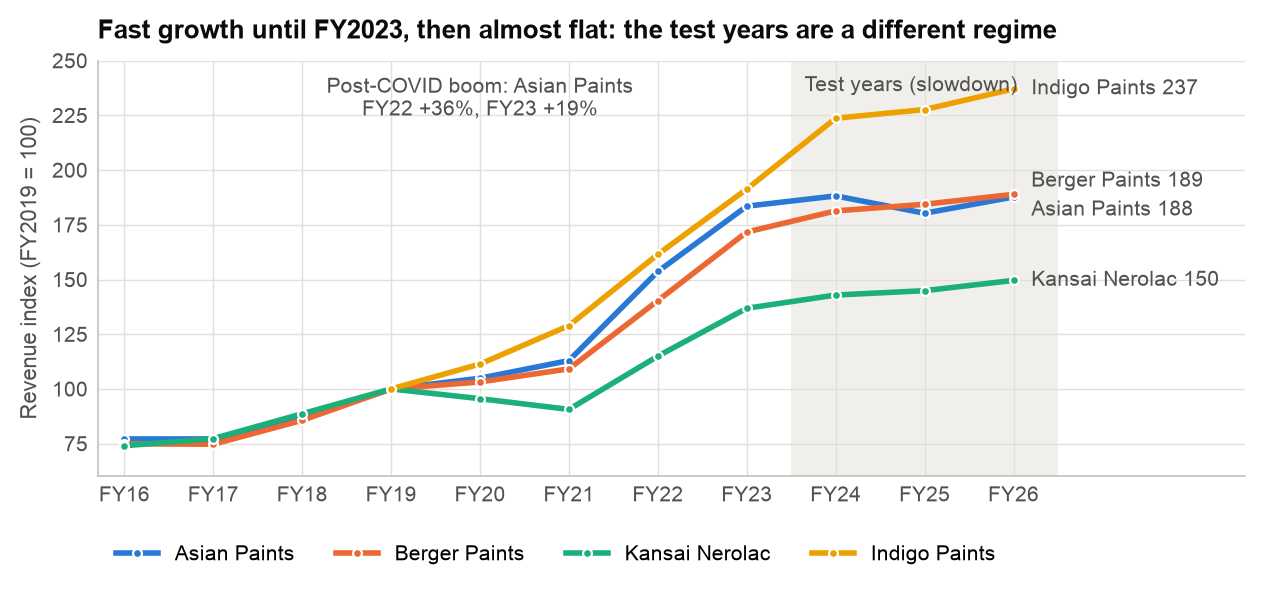

In [3]:
display(Image(FIG / 'revenue_index.png', width=900))

Two things matter for modelling:
* companies differ in size by **more than 20x**, so a model that predicts crore can look accurate (high R²) just by knowing who is big;
* growth was fast until FY2023 and then almost flat, so the test years are a **different regime** from the training years.

## 2. Framing: predict growth, not crore
Each row is a forecast made at the end of quarter *t* for quarter *t+1*. The target is next quarter's year-on-year log growth

$$y = \log R_{t+1} - \log R_{t-3}, \qquad \hat R_{t+1} = R_{t-3}\, e^{\hat y}.$$

Inputs use data up to *t* only (a unit test scrambles the future and checks that past features do not move).

In [4]:
feat = build_features(panel, 'Q')
cols = ['period', 'revenue', 'yoy_0', 'yoy_3', 'gm_chg', 'industry_yoy', 'base_revenue', 'target_period', 'y']
feat.loc[feat['company'] == 'Asian Paints', cols].tail(4)

,period,revenue,yoy_0,yoy_3,gm_chg,industry_yoy,base_revenue,target_period,y
44,FY2026 Q1,7868.45,-0.002,-0.067,0.211,0.010,6868.37,FY2026 Q2,0.069
45,FY2026 Q2,7356.29,0.069,-0.078,2.493,0.029,7320.53,FY2026 Q3,0.041
46,FY2026 Q3,7624.50,0.041,-0.039,1.684,0.028,7192.41,FY2026 Q4,0.096
47,FY2026 Q4,7920.24,0.096,-0.002,0.596,0.079,7868.45,FY2027 Q1,NaN


## 3. Walk-forward backtest: machine learning vs simple rules
At every forecast origin the models are re-trained only on quarters whose results were already published, then forecast the next quarter. The ML models learn a *correction* to the best rule ("same quarter last year x latest YoY growth"), so when they find no signal they fall back to the rule.

Below: the test window FY2024 Q1 to FY2026 Q4 (48 forecasts), run live.

In [5]:
rules = baselines('Q')
ml = {k: v for k, v in ml_models('Q').items() if k in ('Ridge', 'Ensemble (Ridge + RF + LightGBM)')}
live = walk_forward(feat, {**rules, **ml}, 'Q', 'FY2024 Q1', 'FY2026 Q4', verbose=False)
summarize(live, 'Same quarter last year x latest YoY growth', 'Same quarter last year')[['model', 'family', 'MAPE %', 'Rel. MAE', 'DM p-value']].round(3)

,model,family,MAPE %,Rel. MAE,DM p-value
0,Same quarter last year x latest YoY growth,Baseline,3.993,0.951,NaN
1,Ensemble (Ridge + RF + LightGBM),ML,4.013,0.981,0.853
2,Ridge,ML,4.035,1.000,0.702
3,Same quarter last year,Baseline,4.576,1.000,0.768
4,Same quarter last year x 4-qtr avg growth,Baseline,4.842,1.298,0.025
5,Same as last quarter,Baseline,10.198,2.033,0.000


`Rel. MAE` < 1 means more accurate than "same quarter last year". `DM p-value` is a Diebold-Mariano test against the best rule: values far above 0.05 mean the difference is not statistically meaningful.

## 4. Deep learning
Two small PyTorch models sized for ~150 training rows: an MLP and a GRU that reads the last four quarters as a sequence. Early stopping uses the most recent training quarters (never the test window), then the network is refit on all training rows. One seed here to keep it quick; the saved results use a 5-seed ensemble.

In [6]:
gru_1seed = {k: v for k, v in dl_models('Q', seeds=1).items() if k.startswith('GRU')}
live_dl = walk_forward(feat, {**rules, **gru_1seed}, 'Q', 'FY2024 Q1', 'FY2026 Q4', verbose=False)
summarize(live_dl, 'Same quarter last year x latest YoY growth', 'Same quarter last year')[['model', 'family', 'MAPE %', 'Rel. MAE']].head(4)

,model,family,MAPE %,Rel. MAE
0,GRU (1 seed),DL,3.833,0.883
1,Same quarter last year x latest YoY growth,Baseline,3.993,0.951
2,Same quarter last year,Baseline,4.576,1.000
3,Same quarter last year x 4-qtr avg growth,Baseline,4.842,1.298


**Full results** (all models, 5-seed ensembles), from `scripts/run_all.py`:

In [7]:
full = pd.read_csv(RES / 'quarterly_summary_test.csv')
full[['model', 'family', 'MAPE %', 'MAE (Cr)', 'Rel. MAE', 'DM p-value']].round(3)

,model,family,MAPE %,MAE (Cr),Rel. MAE,DM p-value
0,GRU (5-seed ensemble),DL,3.836,113.470,0.887,0.581
1,Same quarter last year x latest YoY growth,Baseline,3.993,121.627,0.951,NaN
2,Ensemble (Ridge + RF + LightGBM),ML,4.013,125.457,0.981,0.853
3,Ridge,ML,4.035,127.857,1.000,0.702
4,MLP (5-seed ensemble),DL,4.042,116.545,0.911,0.787
5,Random Forest,ML,4.070,130.297,1.019,0.696
6,LightGBM,ML,4.451,142.468,1.114,0.362
7,Same quarter last year,Baseline,4.576,127.877,1.000,0.768
8,Same quarter last year x 4-qtr avg growth,Baseline,4.842,166.032,1.298,0.025
9,Huber,ML,5.951,188.306,1.473,0.064


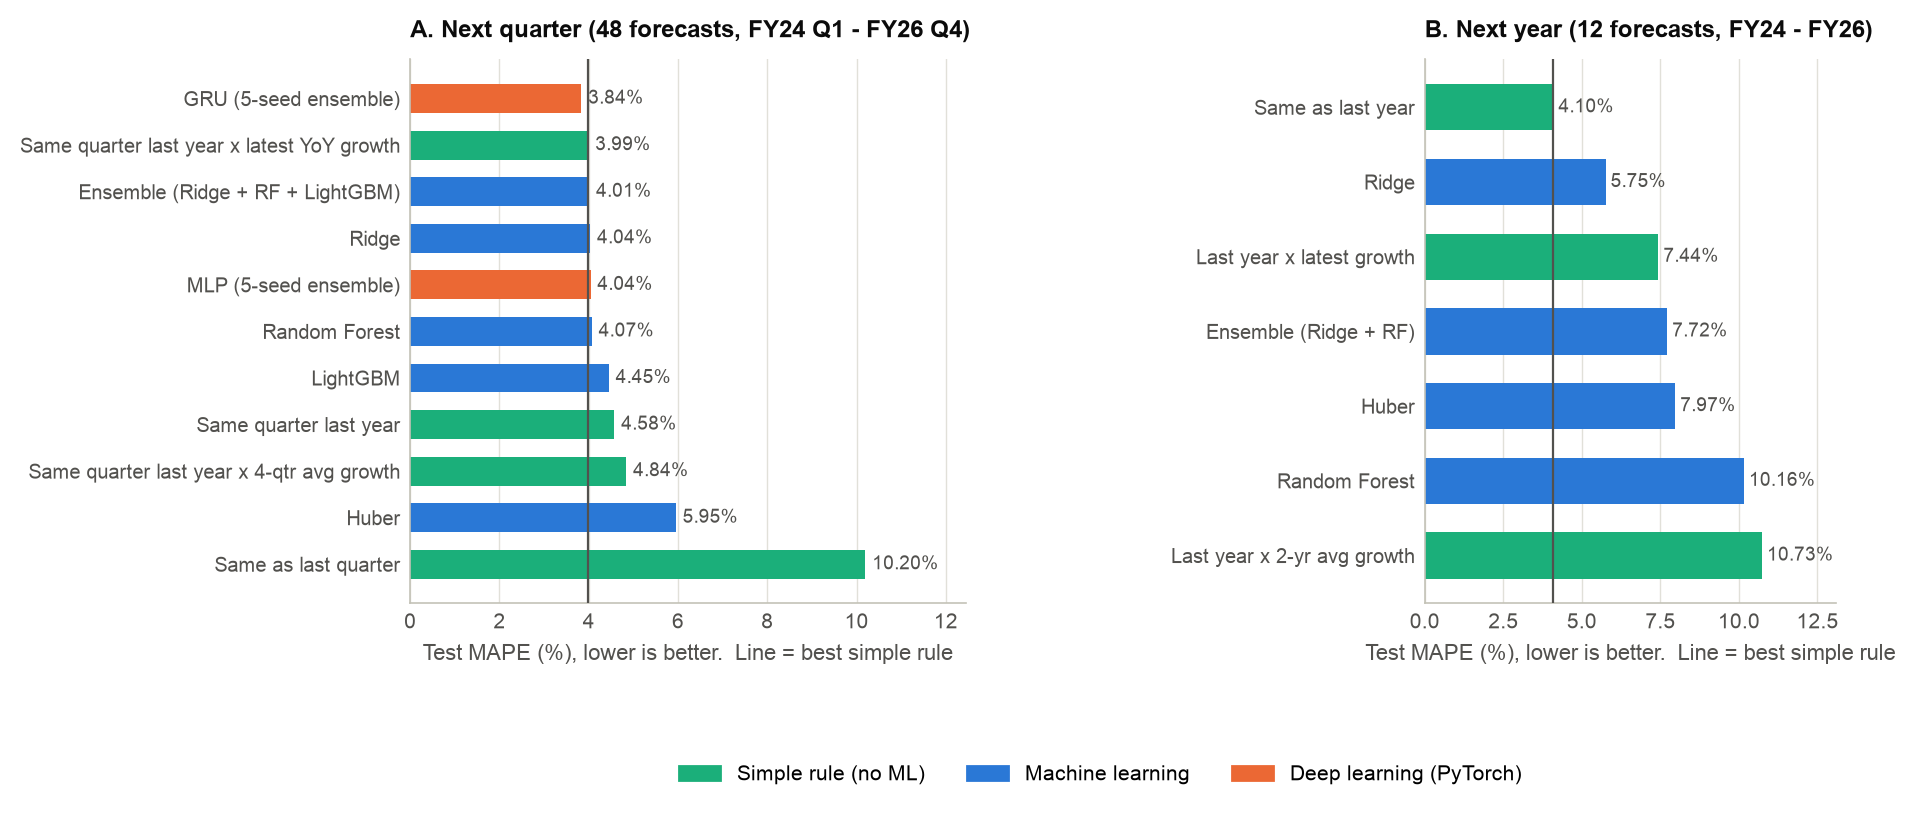

In [8]:
display(Image(FIG / 'leaderboard.png', width=1000))

## 5. Why the v1 project looked good but was not
Same learner (gradient boosting), three framings. Predicting revenue in crore (the v1 approach) is about 2.2x less accurate than predicting growth; the framing matters more than the algorithm.

In [9]:
pd.read_csv(RES / 'quarterly_ablation_test.csv')[['model', 'MAPE %', 'Rel. MAE', 'DM p-value']].round(3)

,model,MAPE %,Rel. MAE,DM p-value
0,Same quarter last year x latest YoY growth,3.993,0.951,NaN
1,GBM on growth (no anchor),4.323,1.084,0.498
2,GBM on growth + residual to rule,4.438,1.055,0.588
3,Same quarter last year,4.576,1.000,0.768
4,GBM on revenue level (v1 framing),9.642,1.334,0.039


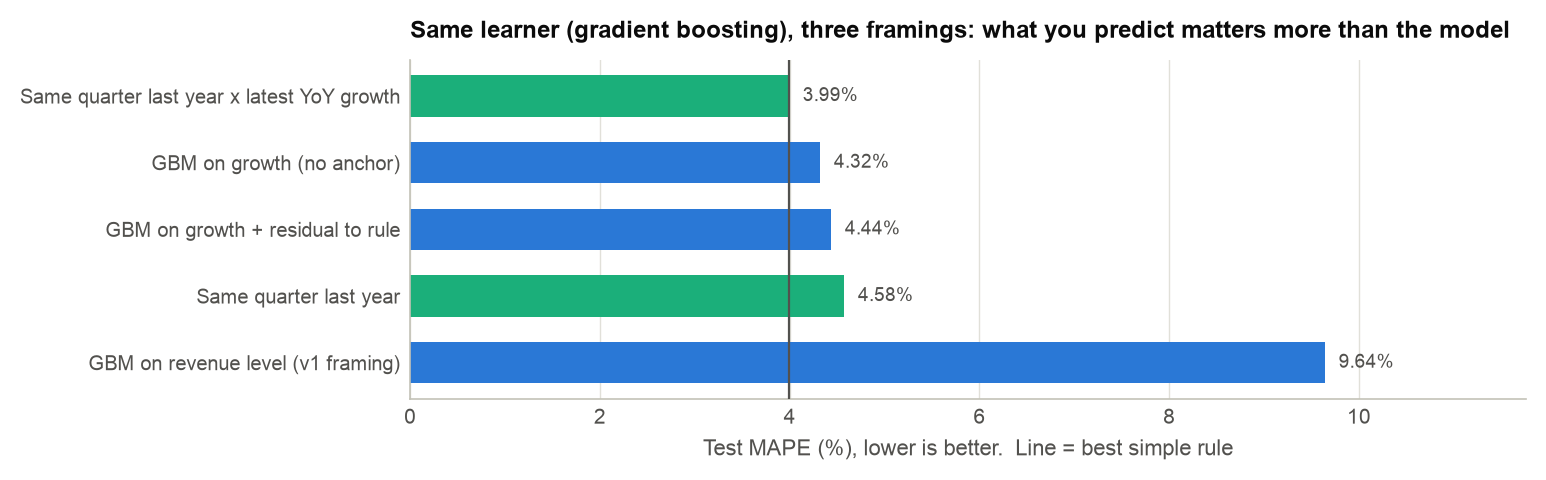

In [10]:
display(Image(FIG / 'ablation_framing.png', width=850))

## 6. Reality check: Q1 FY2027 and management guidance
Q1 FY2027 (April to June 2026) results were published in July and August 2026, after the dataset ends. In May 2026 management flagged price hikes of about 12% and dealer stocking. `data/external/management_guidance_may2026.csv` turns that into one implied growth rate (+10%); edit it to test other readings.

In [11]:
pd.read_csv(RES / 'quarterly_forward_scores.csv').round(2)

,model,family,mean_abs_error_pct
0,Huber,ML,3.48
1,Management guidance,Guidance,3.84
2,LightGBM,ML,4.05
3,Hybrid: GRU (5-seed ensemble) + guidance,Guidance,4.22
4,MLP (5-seed ensemble),DL,4.57
5,GRU (5-seed ensemble),DL,4.60
6,Ensemble (Ridge + RF + LightGBM),ML,4.76
7,Ridge,ML,4.95
8,Random Forest,ML,5.26
9,Same quarter last year x latest YoY growth,Baseline,5.43


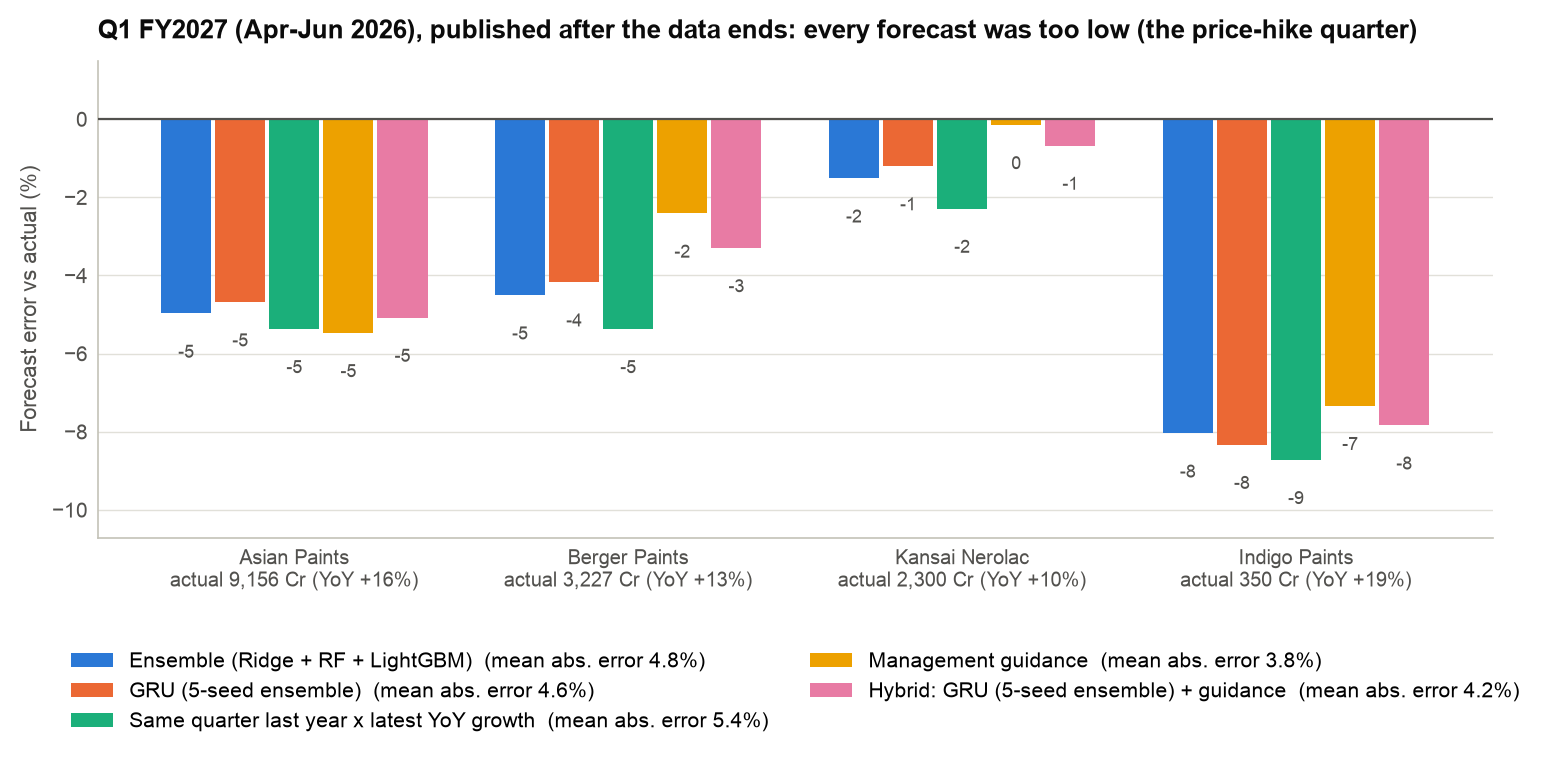

In [12]:
display(Image(FIG / 'q1fy27_check.png', width=1000))

## 7. Conclusions
* **Simple rules are strong.** "Same quarter last year x latest YoY growth" is about 4% off. Any model has to beat that, not zero.
* **Reframed ML and DL now match or slightly beat the rule** (best: GRU, ensemble and Ridge at about 3.8% to 4.0%), versus 9.6% to 9.8% for the v1 framing. On the test window the gains are not statistically significant; in the earlier, more volatile window (FY2019 to FY2023) the ML ensemble beat the rule (6.9% vs 8.2%, p about 0.05).
* **Deep learning is not magic here.** With ~150 rows, early stopping keeps the networks close to the rule; they help a little, not a lot.
* **Turning points need outside information.** In the price-hike quarter every forecast was too low. Guidance (3.8% off) was among the closest; Huber did slightly better on those four numbers, but it was the weakest ML model over the 48-quarter test, so one quarter is anecdotal. The next step is to feed guidance and input-cost data into the models.